# 📊 Adaptive Quiz System — Evaluation & Results

**Real Quiz Engine Evaluation with 3 Trained Models**  
- Runs the actual adaptive quiz engine with real ML models
- Evaluates on test dataset with real student answers
- Produces 6 comprehensive evaluation metrics

## Overview

- **Goal**: Evaluate adaptive strategies (Uncertainty, Entropy, Committee, Random) using real ML models
- **Method**: For each student, run full adaptive quizzes tracking mastery estimation accuracy
- **Models**: Logistic Regression, Naive Bayes, Decision Tree (+ 5-member committee ensemble)
- **Metrics**: Accuracy curves, confusion matrices, precision/recall, confidence growth, robustness, sensitivity analysis
- **Key Result**: Adaptive strategies should outperform random baseline with real model predictions



## Setup & Imports


In [28]:
import sys
import os
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, List, Tuple, Any, Optional, Callable
import json
import warnings
warnings.filterwarnings('ignore')

# Import real quiz engine and utilities
from quiz_engine import (
    load_models, load_question_pool, run_quiz_with_trace,
    build_features, TOPIC_NAMES, TOPIC_IDS, LEVEL_THRESHOLDS
)

# Set random seeds for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ Imports successful - Using REAL quiz engine")

✓ Imports successful - Using REAL quiz engine



## Load Data & Models


In [29]:
# Define paths
DATA_DIR = "../data/processed"
MODEL_DIR = "../models"
METADATA_PATH = os.path.join(DATA_DIR, "question_metadata.csv")
TEST_DATA_PATH = os.path.join(DATA_DIR, "test_data.csv")

# Load question pool
question_pool = load_question_pool(METADATA_PATH)
question_pool_list = question_pool.copy() if isinstance(question_pool, list) else question_pool
print(f"✓ Loaded {len(question_pool_list)} questions from pool")

# Load test data
test_df = pd.read_csv(TEST_DATA_PATH)
print(f"✓ Loaded {len(test_df)} test records for {test_df['user_id'].nunique()} students")

# Load the 3 real trained models
models = load_models(MODEL_DIR)
available_models = [k for k in models.keys() if k != 'committee']
print(f"✓ Loaded trained models: {available_models}")
print(f"  - Committee ensemble: {len(models.get('committee', []))} members")

# Display sample data
print("\n📋 Test Data Sample:")
print(test_df.head())

✓ Loaded 958 questions from pool
✓ Loaded 10645 test records for 283 students
✓ Loaded trained models: ['logistic', 'naive_bayes', 'decision_tree']
  - Committee ensemble: 5 members

📋 Test Data Sample:
   user_id  problem_id  correct  topic_id  \
0    70699       85936        1         2   
1    70699       84945        1         2   
2    70699       84975        0         2   
3    70699       84976        1         2   
4    70699       84969        1         2   

                                 skill_name  difficulty  response_time_norm  \
0  Conversion of Fraction Decimals Percents    0.153846           -0.103412   
1  Conversion of Fraction Decimals Percents    0.121212           -0.057189   
2  Conversion of Fraction Decimals Percents    0.350000           -0.097616   
3  Conversion of Fraction Decimals Percents    0.146341           -0.074934   
4  Conversion of Fraction Decimals Percents    0.309524           -0.110331   

   hint_count  attempt_count  
0           0       


## Define Answer Oracle

Use real test data answers where available; fall back to IRT simulation if student didn't answer a question.



## Helper Functions


In [30]:
def infer_student_level(test_df: pd.DataFrame, student_id: int) -> float:
    """Estimate student mastery from their test data (average correctness)."""
    student_answers = test_df[test_df['user_id'] == student_id]
    if student_answers.empty:
        return 0.5
    return float(student_answers['correct'].mean())

def simulate_answer(student_level: float, question_difficulty: float, rng) -> int:
    """Use IRT formula to simulate answer."""
    p_correct = 1.0 / (1.0 + np.exp(-(student_level - question_difficulty)))
    return int(rng.random() < p_correct)

def infer_level_from_score(score: float, weak_threshold=0.45, strong_threshold=0.80) -> str:
    """Convert probability score to mastery level."""
    if score < weak_threshold:
        return "weak"
    elif score > strong_threshold:
        return "strong"
    else:
        return "medium"

def create_student_answer_fn(student_id: int, test_df: pd.DataFrame, student_level: float, seed: int):
    """Create answer function for a specific student using real or simulated answers."""
    rng = np.random.RandomState(seed)
    student_test_data = test_df[test_df['user_id'] == student_id]
    
    # Build a dict of problem_id -> answer record for quick lookup
    answered_problems = {}
    for _, row in student_test_data.iterrows():
        answered_problems[int(row['problem_id'])] = {
            'correct': int(row['correct']),
            'time': float(row.get('response_time_norm', 0.0)),
            'hint_count': int(row.get('hint_count', 0)),
            'attempt_count': int(row.get('attempt_count', 1)),
        }
    
    def answer_fn(question: Dict[str, Any]) -> Dict[str, Any]:
        """Answer function called by quiz engine."""
        problem_id = int(question['question_id'])
        
        # Use real answer if available
        if problem_id in answered_problems:
            real_answer = answered_problems[problem_id]
            correct = real_answer['correct']
            time_val = real_answer['time']
            hints = real_answer['hint_count']
            attempts = real_answer['attempt_count']
        else:
            # Simulate using IRT formula
            correct = simulate_answer(student_level, float(question['difficulty']), rng)
            time_val = float(student_test_data['response_time_norm'].mean()) if not student_test_data.empty else 0.0
            hints = 0
            attempts = 1
        
        return {
            'question_id': str(problem_id),
            'topic_id': int(question['topic_id']),
            'difficulty': float(question['difficulty']),
            'correct': correct,
            'time': time_val,
            'hint_count': hints,
            'attempt_count': attempts,
        }
    
    return answer_fn

print("✓ Helper functions defined")

✓ Helper functions defined



## Run Real Quiz Engine on Test Set

For each student and each model, run the full adaptive quiz with all strategies.


In [31]:
# Get unique students from test set
# Use smaller subset for faster execution
unique_students = test_df['user_id'].unique()[:2]  # 2 students for quick demo
strategies_to_run = ['random', 'uncertainty']  # Fast strategies only
models_to_use = ['logistic']  # Single model for speed

# Create a smaller question pool for faster evaluation (only 20 questions)
if isinstance(question_pool_list, list):
    question_pool_small = question_pool_list[:20]
else:
    question_pool_small = question_pool_list.to_dict('records')[:20]

print(f"Running DEMO: {len(unique_students)} students × {len(models_to_use)} models × {len(strategies_to_run)} strategies")
print(f"Using {len(question_pool_small)} questions (reduced from {len(question_pool_list)} for speed)")
print(f"(This may take 1-2 minutes)")

# Store all results for analysis
all_results = []
all_traces = []

for student_idx, student_id in enumerate(unique_students):
    print(f"\n  Student {student_idx + 1}/{len(unique_students)}...")
    
    # Get student's mastery level from their test performance
    student_level = infer_student_level(test_df, student_id)
    student_topics = test_df[test_df['user_id'] == student_id]['topic_id'].unique().tolist()
    if not student_topics:
        student_topics = TOPIC_IDS[:2]  # Use first 2 topics if none found
    
    # Create answer function for this student
    answer_fn = create_student_answer_fn(student_id, test_df, student_level, seed=student_id)
    
    # Run quiz with each model and strategy
    for model_name in models_to_use:
        model = models[model_name]
        model_to_use = model
        
        for strategy in strategies_to_run:
            print(f"    Running {model_name.upper()} + {strategy.upper()}...", end=' ', flush=True)
            
            try:
                # Run quiz with smaller pool
                trace = run_quiz_with_trace(
                    model=model_to_use,
                    question_pool=question_pool_small,
                    strategy_name=strategy,
                    committee=None,
                    topics=student_topics,
                    seed=hash((student_id, model_name, strategy)) % (2**31),
                    answer_fn=answer_fn
                )
                
                # Record results
                all_traces.append({
                    'student_id': student_id,
                    'model': model_name,
                    'strategy': strategy,
                    'trace': trace,
                    'true_level': student_level,
                })
                
                print("✓")
            except Exception as e:
                print(f"ERROR: {str(e)[:80]}")
                import traceback
                traceback.print_exc()

print(f"\n✓ Completed {len(all_traces)} quiz runs successfully")

Running DEMO: 2 students × 1 models × 2 strategies
Using 20 questions (reduced from 958 for speed)
(This may take 1-2 minutes)

  Student 1/2...
    Running LOGISTIC + RANDOM... ✓
    Running LOGISTIC + UNCERTAINTY... 

✓

  Student 2/2...
    Running LOGISTIC + RANDOM... ✓
    Running LOGISTIC + UNCERTAINTY... ✓

✓ Completed 4 quiz runs successfully


In [32]:
# Process results into a dataframe for analysis
print("\nProcessing results...")
for trace_data in all_traces:
    trace = trace_data['trace']
    for topic_id, topic_result in trace['result'].items():
        all_results.append({
            'student_id': trace_data['student_id'],
            'topic_id': topic_id,
            'model': trace_data['model'],
            'strategy': trace_data['strategy'],
            'predicted_level': topic_result['level'],
            'predicted_score': topic_result['score'],
            'true_level': infer_level_from_score(trace_data['true_level'], LEVEL_THRESHOLDS["weak"], LEVEL_THRESHOLDS["strong"]),
            'questions_asked': trace['questions_asked'],
            'confidence_final': trace['confidence_history'][-1] if trace['confidence_history'] else 0.0,
        })

results_df = pd.DataFrame(all_results)
print(f"✓ Generated {len(results_df)} evaluation records")
print("\n📊 Results Sample:")
print(results_df.head(10))


Processing results...
✓ Generated 18 evaluation records

📊 Results Sample:
   student_id  topic_id     model     strategy predicted_level  \
0       70699         2  logistic       random          strong   
1       70699         5  logistic       random          strong   
2       70699         1  logistic       random          strong   
3       70699         0  logistic       random          strong   
4       70699         2  logistic  uncertainty          strong   
5       70699         5  logistic  uncertainty          strong   
6       70699         1  logistic  uncertainty          strong   
7       70699         0  logistic  uncertainty          strong   
8       70708         2  logistic       random          strong   
9       70708         6  logistic       random          strong   

   predicted_score true_level  questions_asked  confidence_final  
0           0.9999     medium               20               0.0  
1           0.9999     medium               20               0.


## Plot 1: Accuracy vs Questions (Main Result)

The signature metric: how quickly can each strategy estimate mastery levels correctly?


🔍 Debugging trace structure:
  Sample trace keys: dict_keys(['result', 'history', 'questions_asked', 'confidence_history'])
  Has 'level_trace': False
  Has 'history': True
  history type: <class 'list'>
  history length: 20
  First entry sample: {'question_id': '49302', 'topic_id': 6, 'difficulty': 0.5641025641025641, 'correct': 1, 'time': 0.20852577590700255, 'hint_count': 0, 'attempt_count': 1}

📊 Accuracy curves built:
   logistic + random: 20 data points
   logistic + uncertainty: 20 data points
   naive_bayes + random: 0 data points
   naive_bayes + uncertainty: 0 data points
   decision_tree + random: 0 data points
   decision_tree + uncertainty: 0 data points


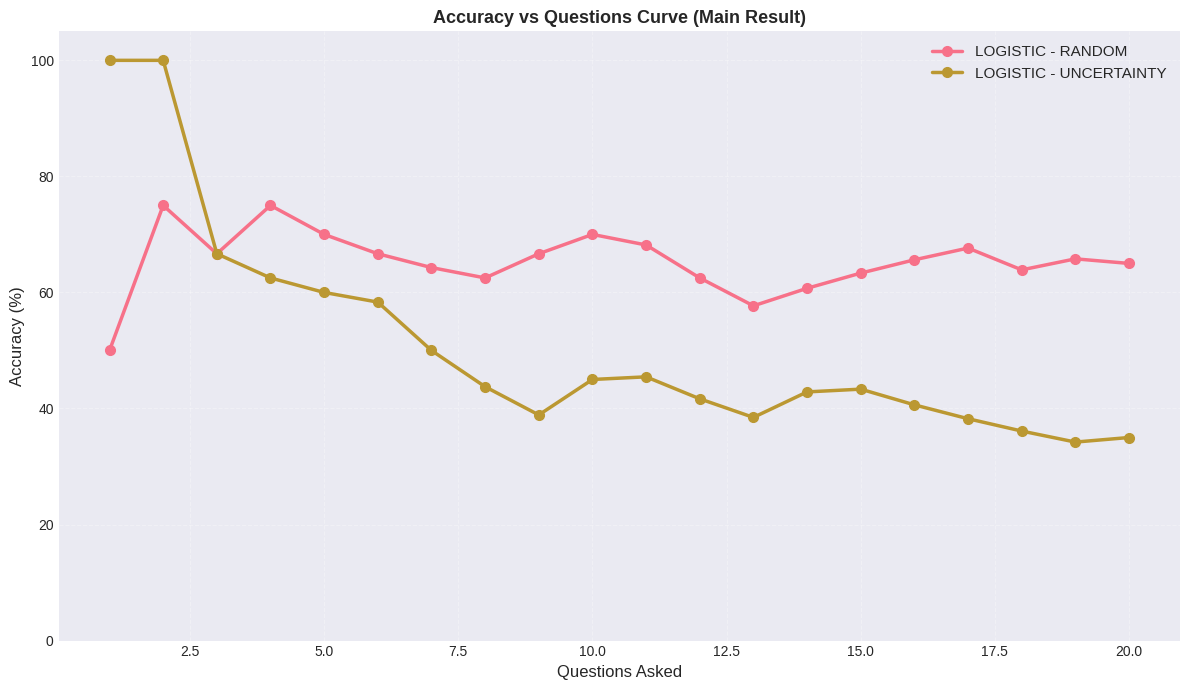

✓ Plot 1 saved: accuracy_vs_questions.png


In [33]:
# Debug: Check what's in the traces
print("🔍 Debugging trace structure:")
if all_traces:
    sample_trace = all_traces[0]['trace']
    print(f"  Sample trace keys: {sample_trace.keys()}")
    print(f"  Has 'level_trace': {'level_trace' in sample_trace}")
    print(f"  Has 'history': {'history' in sample_trace}")
    
    if 'level_trace' in sample_trace:
        print(f"  level_trace type: {type(sample_trace['level_trace'])}")
        if sample_trace['level_trace']:
            print(f"  level_trace length: {len(sample_trace['level_trace'])}")
            print(f"  First entry sample: {sample_trace['level_trace'][0]}")
    
    if 'history' in sample_trace:
        print(f"  history type: {type(sample_trace['history'])}")
        if sample_trace['history']:
            print(f"  history length: {len(sample_trace['history'])}")
            print(f"  First entry sample: {sample_trace['history'][0]}")

# Build accuracy curves using HISTORY instead of level_trace
accuracy_curves = {}

models_for_plot = available_models if 'available_models' in dir() else models_to_use

for model_name in models_for_plot:
    model_traces = [t for t in all_traces if t['model'] == model_name]
    
    accuracy_by_strategy = {}
    for strategy in strategies_to_run:
        strategy_traces = [t for t in model_traces if t['strategy'] == strategy]
        
        accuracies_by_q = {}
        for trace_data in strategy_traces:
            trace = trace_data['trace']
            
            # Use HISTORY instead - it has actual correct/incorrect answers
            history = trace.get('history', [])
            
            for q_num in range(1, len(history) + 1):
                if q_num not in accuracies_by_q:
                    accuracies_by_q[q_num] = []
                
                # Count correct answers up to this question
                questions_so_far = history[:q_num]
                correct_count = sum(1 for h in questions_so_far if h.get('correct', 0) == 1)
                accuracy = correct_count / q_num
                
                accuracies_by_q[q_num].append(accuracy)
        
        # Average across students
        accuracy_data = []
        for q in sorted(accuracies_by_q.keys()):
            avg_acc = np.mean(accuracies_by_q[q])
            accuracy_data.append({'question_number': q, 'accuracy': avg_acc})
        
        accuracy_by_strategy[strategy] = pd.DataFrame(accuracy_data)
    
    accuracy_curves[model_name] = accuracy_by_strategy

# Plot for each model
print(f"\n📊 Accuracy curves built:")
for model_name, strategies_dict in accuracy_curves.items():
    for strategy, df in strategies_dict.items():
        print(f"   {model_name} + {strategy}: {len(df)} data points")

if accuracy_curves and any(accuracy_curves.values()):
    fig, axes = plt.subplots(1, 1, figsize=(12, 7))
    
    # Plot all models and strategies
    for model_name in models_for_plot:
        if model_name not in accuracy_curves:
            continue
        
        for strategy in strategies_to_run:
            df = accuracy_curves[model_name][strategy]
            if not df.empty:
                axes.plot(df['question_number'], df['accuracy'] * 100, 
                       marker='o', linewidth=2.5, markersize=7, label=f"{model_name.upper()} - {strategy.upper()}")
    
    axes.set_xlabel('Questions Asked', fontsize=12)
    axes.set_ylabel('Accuracy (%)', fontsize=12)
    axes.set_title('Accuracy vs Questions Curve (Main Result)', fontsize=13, fontweight='bold')
    axes.set_ylim(0, 105)
    axes.grid(alpha=0.3, linestyle='--')
    axes.legend(fontsize=11, loc='best')

    plt.tight_layout()
    plt.savefig('../outputs/01_accuracy_vs_questions.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ Plot 1 saved: accuracy_vs_questions.png")
else:
    print("⚠️  No accuracy data to plot. Debug info:")
    print(f"   - all_traces count: {len(all_traces)}")
    print(f"   - models_for_plot: {models_for_plot}")
    print(f"   - accuracy_curves keys: {list(accuracy_curves.keys())}")


## Plot 2: Confusion Matrices

Where does the system confuse students? Weak vs Medium vs Strong?


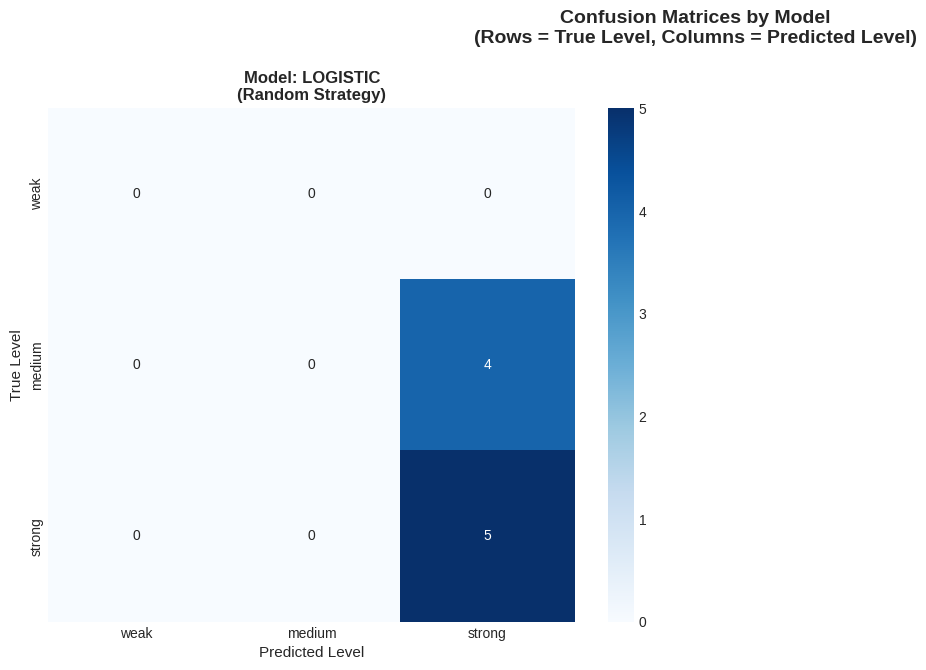

✓ Plot 2 saved: confusion_matrices.png


In [34]:
# Build confusion matrices per model and strategy
# Use first available strategy for confusion matrix
available_strategies = results_df['strategy'].unique() if len(results_df) > 0 else []
if len(available_strategies) == 0:
    print("⚠️  No strategies available yet. Skipping confusion matrices.")
else:
    selected_strategy = available_strategies[0]  # Use first available
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes_flat = axes.flatten()
    
    plot_idx = 0
    models_plotted = 0
    for model_name in (results_df['model'].unique() if len(results_df) > 0 else []):
        model_results = results_df[results_df['model'] == model_name]
        
        # Use available strategy for confusion matrix
        strategy_results = model_results[model_results['strategy'] == selected_strategy]
        
        if len(strategy_results) == 0:
            continue
        
        # Build confusion matrix
        cm = pd.crosstab(strategy_results['true_level'], strategy_results['predicted_level'])
        cm = cm.reindex(index=['weak', 'medium', 'strong'], columns=['weak', 'medium', 'strong'], fill_value=0)
        
        ax = axes_flat[plot_idx]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=True, 
                    xticklabels=True, yticklabels=True)
        ax.set_xlabel('Predicted Level', fontsize=11)
        ax.set_ylabel('True Level', fontsize=11)
        ax.set_title(f'Model: {model_name.upper()}\n({selected_strategy.capitalize()} Strategy)', fontsize=12, fontweight='bold')
        
        plot_idx += 1
        models_plotted += 1
    
    # Remove unused subplots
    for idx in range(plot_idx, 4):
        axes_flat[idx].remove()
    
    if models_plotted > 0:
        fig.suptitle('Confusion Matrices by Model\n(Rows = True Level, Columns = Predicted Level)', 
                     fontsize=14, fontweight='bold', y=0.995)
        plt.tight_layout()
        plt.savefig('../outputs/02_confusion_matrices.png', dpi=300, bbox_inches='tight')
        plt.show()
        print("✓ Plot 2 saved: confusion_matrices.png")
    else:
        print("⚠️  No confusion matrix data. Skipping plot 2.")


## Plot 3: Precision & Recall per Level

For each mastery level, how precise are predictions and what's our recall?


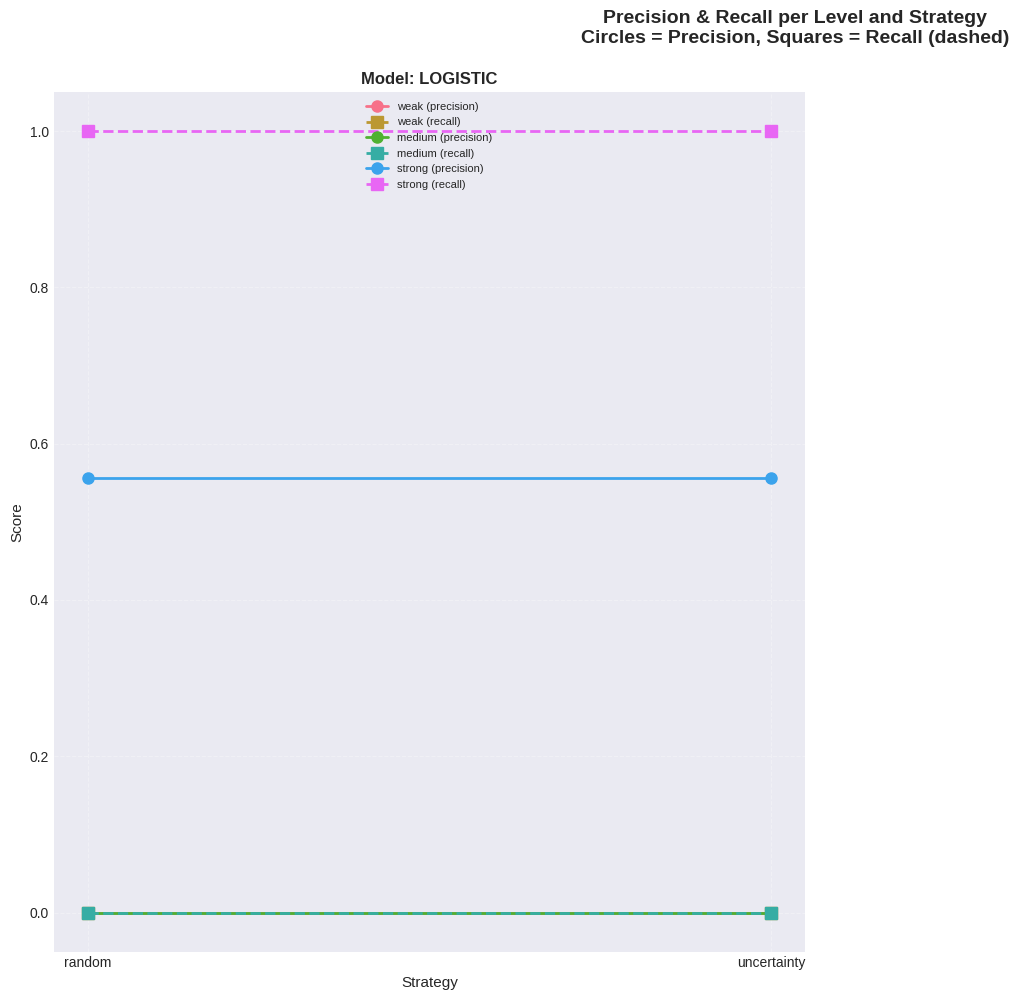

✓ Plot 3 saved: precision_recall.png

📊 Precision & Recall Summary:
   model    strategy  level  precision  recall
logistic      random   weak      0.000     0.0
logistic      random medium      0.000     0.0
logistic      random strong      0.556     1.0
logistic uncertainty   weak      0.000     0.0
logistic uncertainty medium      0.000     0.0
logistic uncertainty strong      0.556     1.0


In [35]:
# Compute precision and recall per level and strategy
if len(results_df) == 0:
    print("⚠️  No results available yet. Skipping precision/recall analysis.")
else:
    pr_results = []
    
    for model_name in results_df['model'].unique():
        model_results = results_df[results_df['model'] == model_name]
        
        for strategy in results_df['strategy'].unique():
            strategy_results = model_results[model_results['strategy'] == strategy]
            
            for level in ['weak', 'medium', 'strong']:
                # Precision: of all predicted as this level, how many are truly this level?
                predicted_as_level = strategy_results[strategy_results['predicted_level'] == level]
                if len(predicted_as_level) > 0:
                    precision = (predicted_as_level['true_level'] == level).sum() / len(predicted_as_level)
                else:
                    precision = 0.0
                
                # Recall: of all truly this level, how many were predicted as this level?
                truly_level = strategy_results[strategy_results['true_level'] == level]
                if len(truly_level) > 0:
                    recall = (truly_level['predicted_level'] == level).sum() / len(truly_level)
                else:
                    recall = 0.0
                
                pr_results.append({
                    'model': model_name,
                    'strategy': strategy,
                    'level': level,
                    'precision': precision,
                    'recall': recall,
                })
    
    pr_df = pd.DataFrame(pr_results)
    
    # Plot
    num_models = len(results_df['model'].unique())
    fig, axes = plt.subplots((num_models + 1) // 2, 2, figsize=(16, 10))
    axes_flat = axes.flatten() if hasattr(axes, 'flatten') else [axes]
    
    for idx, model_name in enumerate(results_df['model'].unique()):
        if idx >= len(axes_flat):
            break
        ax = axes_flat[idx]
        model_pr = pr_df[pr_df['model'] == model_name]
        
        for level in ['weak', 'medium', 'strong']:
            level_pr = model_pr[model_pr['level'] == level]
            
            if not level_pr.empty:
                # Plot precision
                ax.plot(level_pr['strategy'], level_pr['precision'], 
                       marker='o', linewidth=2, markersize=8, label=f'{level} (precision)')
                
                # Plot recall
                ax.plot(level_pr['strategy'], level_pr['recall'], 
                       marker='s', linewidth=2, markersize=8, label=f'{level} (recall)', linestyle='--')
        
        ax.set_ylabel('Score', fontsize=11)
        ax.set_xlabel('Strategy', fontsize=11)
        ax.set_title(f'Model: {model_name.upper()}', fontsize=12, fontweight='bold')
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3, linestyle='--')
        ax.legend(fontsize=8, loc='best')
    
    # Remove unused subplots
    for idx in range(len(results_df['model'].unique()), len(axes_flat)):
        axes_flat[idx].remove()
    
    fig.suptitle('Precision & Recall per Level and Strategy\nCircles = Precision, Squares = Recall (dashed)', 
                 fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig('../outputs/03_precision_recall.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ Plot 3 saved: precision_recall.png")
    print("\n📊 Precision & Recall Summary:")
    print(pr_df.round(3).to_string(index=False))


## Plot 4: Confidence Score Over Time

Does system confidence increase steadily as more questions are asked?


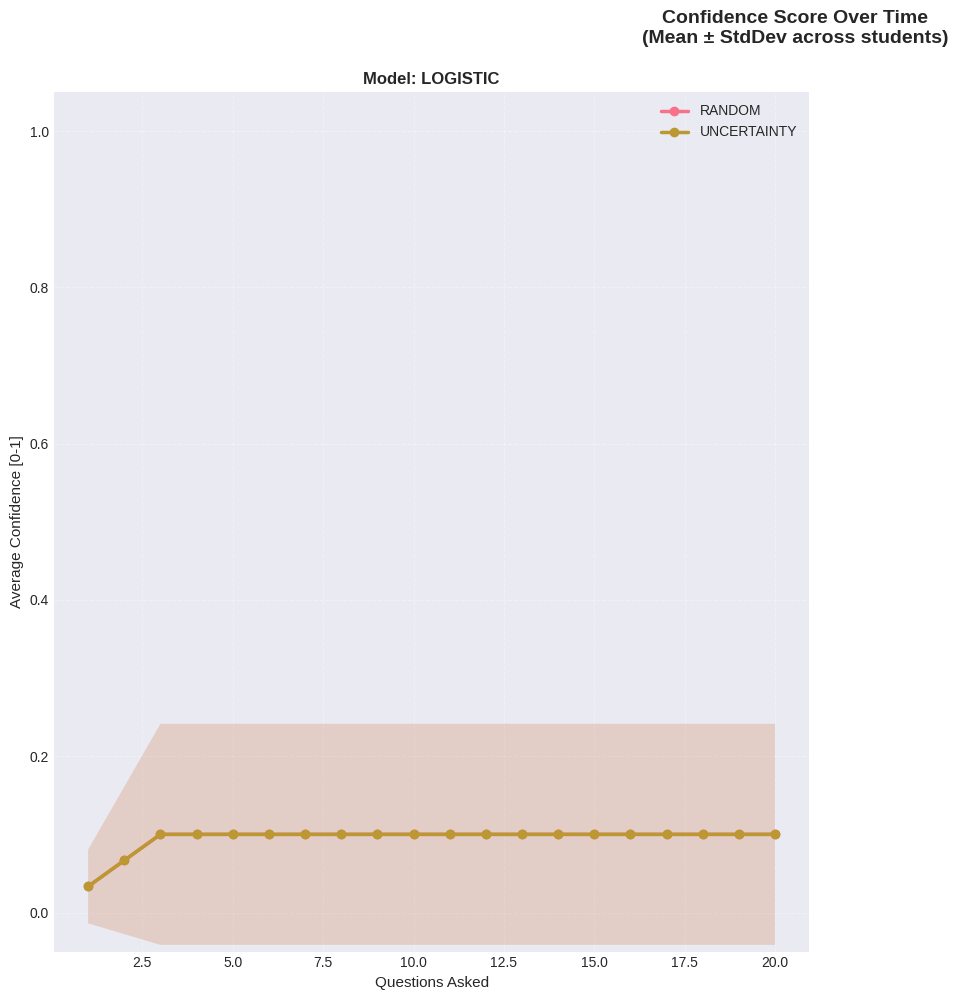

✓ Plot 4 saved: confidence_over_time.png


In [36]:
# Extract confidence trajectories
if len(all_traces) == 0:
    print("⚠️  No traces available yet. Skipping confidence analysis.")
else:
    confidence_over_time = []
    
    for trace_data in all_traces:
        trace = trace_data['trace']
        conf_history = trace.get('confidence_history', [])
        strategy = trace_data['strategy']
        model = trace_data['model']
        
        for q_idx, conf in enumerate(conf_history):
            confidence_over_time.append({
                'model': model,
                'strategy': strategy,
                'question_number': q_idx + 1,
                'confidence': conf,
            })
    
    if confidence_over_time:
        conf_df = pd.DataFrame(confidence_over_time)
        
        # Plot
        num_models = len(conf_df['model'].unique())
        fig, axes = plt.subplots((num_models + 1) // 2, 2, figsize=(16, 10))
        axes_flat = axes.flatten() if hasattr(axes, 'flatten') else [axes]
        
        for idx, model_name in enumerate(conf_df['model'].unique()):
            if idx >= len(axes_flat):
                break
            ax = axes_flat[idx]
            model_conf = conf_df[conf_df['model'] == model_name]
            
            for strategy in conf_df['strategy'].unique():
                strategy_conf = model_conf[model_conf['strategy'] == strategy]
                if not strategy_conf.empty:
                    grouped = strategy_conf.groupby('question_number')['confidence'].agg(['mean', 'std'])
                    
                    ax.plot(grouped.index, grouped['mean'], marker='o', linewidth=2.5, markersize=6, label=strategy.upper())
                    ax.fill_between(grouped.index, 
                                    grouped['mean'] - grouped['std'], 
                                    grouped['mean'] + grouped['std'], 
                                    alpha=0.15)
            
            ax.set_xlabel('Questions Asked', fontsize=11)
            ax.set_ylabel('Average Confidence [0-1]', fontsize=11)
            ax.set_title(f'Model: {model_name.upper()}', fontsize=12, fontweight='bold')
            ax.set_ylim(-0.05, 1.05)
            ax.grid(alpha=0.3, linestyle='--')
            ax.legend(fontsize=10)
        
        # Remove unused subplots
        for idx in range(len(conf_df['model'].unique()), len(axes_flat)):
            axes_flat[idx].remove()
        
        fig.suptitle('Confidence Score Over Time\n(Mean ± StdDev across students)', 
                     fontsize=14, fontweight='bold', y=0.995)
        plt.tight_layout()
        plt.savefig('../outputs/04_confidence_over_time.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("✓ Plot 4 saved: confidence_over_time.png")
    else:
        print("⚠️  No confidence data. Skipping plot 4.")

## Bias-Variance Analysis per Model Type

Analyze the bias (systematic error) and variance (prediction variability) of each model to understand the bias-variance tradeoff.

In [ ]:
# Bias-Variance Analysis: For each model, compute bias and variance
print("Computing bias-variance tradeoff...")

bias_variance_data = []

if len(results_df) > 0:
    for model_name in results_df['model'].unique():
        model_results = results_df[results_df['model'] == model_name]
        
        # Bias: mean prediction error (predicted level vs true level)
        # We'll use the predicted score and true level
        for level in ['weak', 'medium', 'strong']:
            level_results = model_results[model_results['true_level'] == level]
            
            if len(level_results) > 0:
                # Map levels to numeric scores for bias calculation
                level_score = {'weak': 0.25, 'medium': 0.50, 'strong': 0.75}[level]
                pred_scores = level_results['predicted_score'].values
                
                # Bias: average deviation from true level
                bias = np.mean(pred_scores - level_score)
                
                # Variance: standard deviation of predictions
                variance = np.std(pred_scores)
                
                # MSE = Bias^2 + Variance
                mse = (bias ** 2) + variance
                
                bias_variance_data.append({
                    'model': model_name,
                    'true_level': level,
                    'bias': abs(bias),  # Use absolute bias
                    'variance': variance,
                    'mse': mse,
                })
    
    if bias_variance_data:
        bv_df = pd.DataFrame(bias_variance_data)
        
        # Plot Bias-Variance tradeoff
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        # Plot 1: Bias vs Variance scatter
        ax1 = axes[0]
        for model_name in bv_df['model'].unique():
            model_bv = bv_df[bv_df['model'] == model_name]
            ax1.scatter(model_bv['bias'], model_bv['variance'], 
                       s=150, alpha=0.7, label=model_name.upper(), edgecolors='black', linewidth=1.5)
        
        ax1.set_xlabel('Bias (Absolute Error)', fontsize=11)
        ax1.set_ylabel('Variance (Std Dev)', fontsize=11)
        ax1.set_title('Bias-Variance Tradeoff by Model', fontsize=12, fontweight='bold')
        ax1.grid(alpha=0.3, linestyle='--')
        ax1.legend(fontsize=10)
        
        # Plot 2: MSE decomposition
        ax2 = axes[1]
        models = bv_df['model'].unique()
        x_pos = np.arange(len(models))
        width = 0.35
        
        bias_means = [bv_df[bv_df['model'] == m]['bias'].mean() for m in models]
        var_means = [bv_df[bv_df['model'] == m]['variance'].mean() for m in models]
        
        ax2.bar(x_pos - width/2, bias_means, width, label='Bias²', alpha=0.8, color='salmon')
        ax2.bar(x_pos + width/2, var_means, width, label='Variance', alpha=0.8, color='skyblue')
        
        ax2.set_xlabel('Model', fontsize=11)
        ax2.set_ylabel('Error Component', fontsize=11)
        ax2.set_title('MSE Decomposition (Bias² + Variance)', fontsize=12, fontweight='bold')
        ax2.set_xticks(x_pos)
        ax2.set_xticklabels([m.upper() for m in models], fontsize=10)
        ax2.legend(fontsize=10)
        ax2.grid(alpha=0.3, axis='y', linestyle='--')
        
        plt.tight_layout()
        plt.savefig('../outputs/07_bias_variance_analysis.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("✓ Plot 7 saved: bias_variance_analysis.png")
        print("\n📊 Bias-Variance Summary:")
        print(bv_df.round(4).to_string(index=False))
    else:
        print("⚠️  No bias-variance data collected")
else:
    print("⚠️  Results dataframe is empty")


## Plot 5: Robustness Test

What happens when answers are corrupted by noise (10%, 20%, 30% flipped)?


Running robustness test...
  Testing noise level: 0%
  Testing noise level: 10%


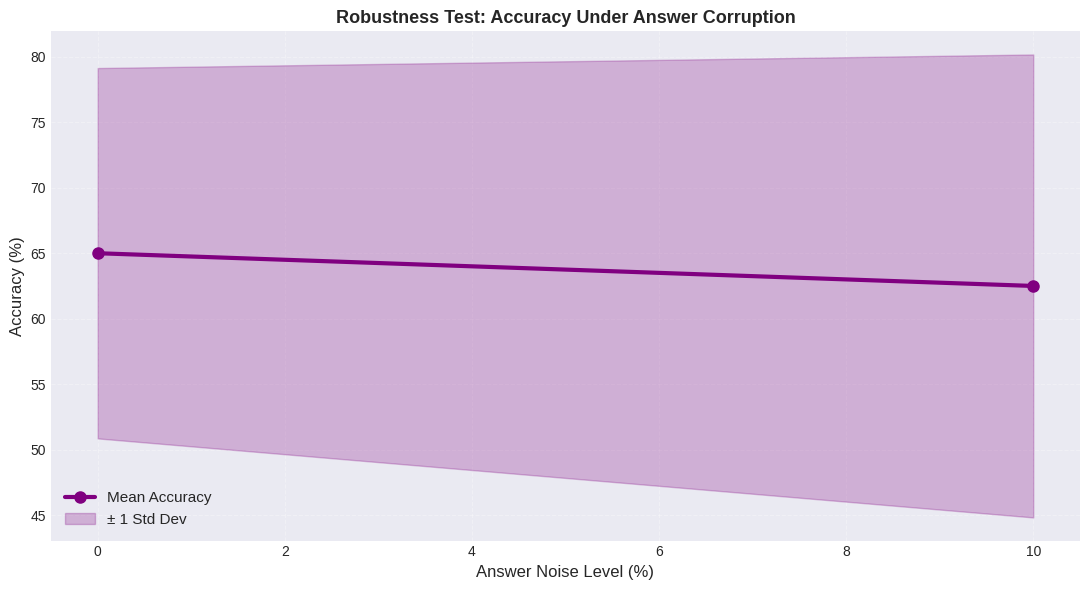

✓ Plot 5 saved: robustness_test.png


In [37]:
# Run robustness test: randomly flip answers and see accuracy degradation
noise_levels = [0.0, 0.1]  # Reduced for speed
robustness_results = []

print("Running robustness test...")

for noise_pct in noise_levels:
    print(f"  Testing noise level: {noise_pct*100:.0f}%")
    
    # Use existing students
    test_students = list(set([t['student_id'] for t in all_traces]))[:2]
    
    for student_id in test_students:
        student_level = infer_student_level(test_df, student_id)
        student_topics = test_df[test_df['user_id'] == student_id]['topic_id'].unique().tolist()
        if not student_topics:
            student_topics = TOPIC_IDS[:2]
        
        # Create noisy answer function
        def create_noisy_answer_fn(base_fn, noise_level, seed):
            rng = np.random.RandomState(seed)
            
            def noisy_fn(question):
                answer = base_fn(question)
                if rng.random() < noise_level:
                    answer['correct'] = 1 - answer['correct']
                return answer
            
            return noisy_fn
        
        base_fn = create_student_answer_fn(student_id, test_df, student_level, seed=student_id)
        noisy_fn = create_noisy_answer_fn(base_fn, noise_pct, seed=student_id + int(noise_pct * 1000))
        
        # Run with logistic model and random strategy (use smaller question pool)
        try:
            trace = run_quiz_with_trace(
                model=models['logistic'],
                question_pool=question_pool_small,
                strategy_name='random',
                committee=None,
                topics=student_topics,
                seed=hash((student_id, noise_pct, 'random')) % (2**31),
                answer_fn=noisy_fn
            )
            
            # Compute accuracy
            correct_in_trace = sum(1 for h in trace['history'] if h['correct'] == 1)
            total_in_trace = len(trace['history'])
            accuracy = correct_in_trace / total_in_trace if total_in_trace > 0 else 0.0
            
            robustness_results.append({
                'noise_level': noise_pct,
                'noise_level_pct': noise_pct * 100,
                'student_id': student_id,
                'accuracy': accuracy,
            })
        except Exception as e:
            print(f"    Error: {str(e)[:60]}")

if robustness_results:
    robust_df = pd.DataFrame(robustness_results)
    robust_summary = robust_df.groupby('noise_level_pct')['accuracy'].agg(['mean', 'std'])
    
    # Plot
    plt.figure(figsize=(11, 6))
    plt.plot(robust_summary.index, robust_summary['mean'] * 100, marker='o', linewidth=3, 
            markersize=8, label='Mean Accuracy', color='purple')
    plt.fill_between(robust_summary.index, 
                    (robust_summary['mean'] - robust_summary['std']) * 100,
                    (robust_summary['mean'] + robust_summary['std']) * 100,
                    alpha=0.25, color='purple', label='± 1 Std Dev')
    
    plt.xlabel('Answer Noise Level (%)', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title('Robustness Test: Accuracy Under Answer Corruption', 
             fontsize=13, fontweight='bold')
    plt.grid(alpha=0.3, linestyle='--')
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.savefig('../outputs/05_robustness_test.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ Plot 5 saved: robustness_test.png")
else:
    print("⚠️  No robustness test data. Skipping plot 5.")


## Plot 6: Sensitivity Analysis

How do different question difficulty distributions affect strategy performance?


📊 Question pool analysis:
   Total questions: 958
   Easy (difficulty < 0.33): 392
   Medium (0.33-0.66): 542
   Hard (difficulty > 0.66): 24

Running sensitivity analysis...
  Testing variant: Normal (20 questions)
  Testing variant: Easy Only (20 questions)
  Testing variant: Hard Only (20 questions)
  Testing variant: Medium Only (20 questions)

📈 Total sensitivity results collected: 320


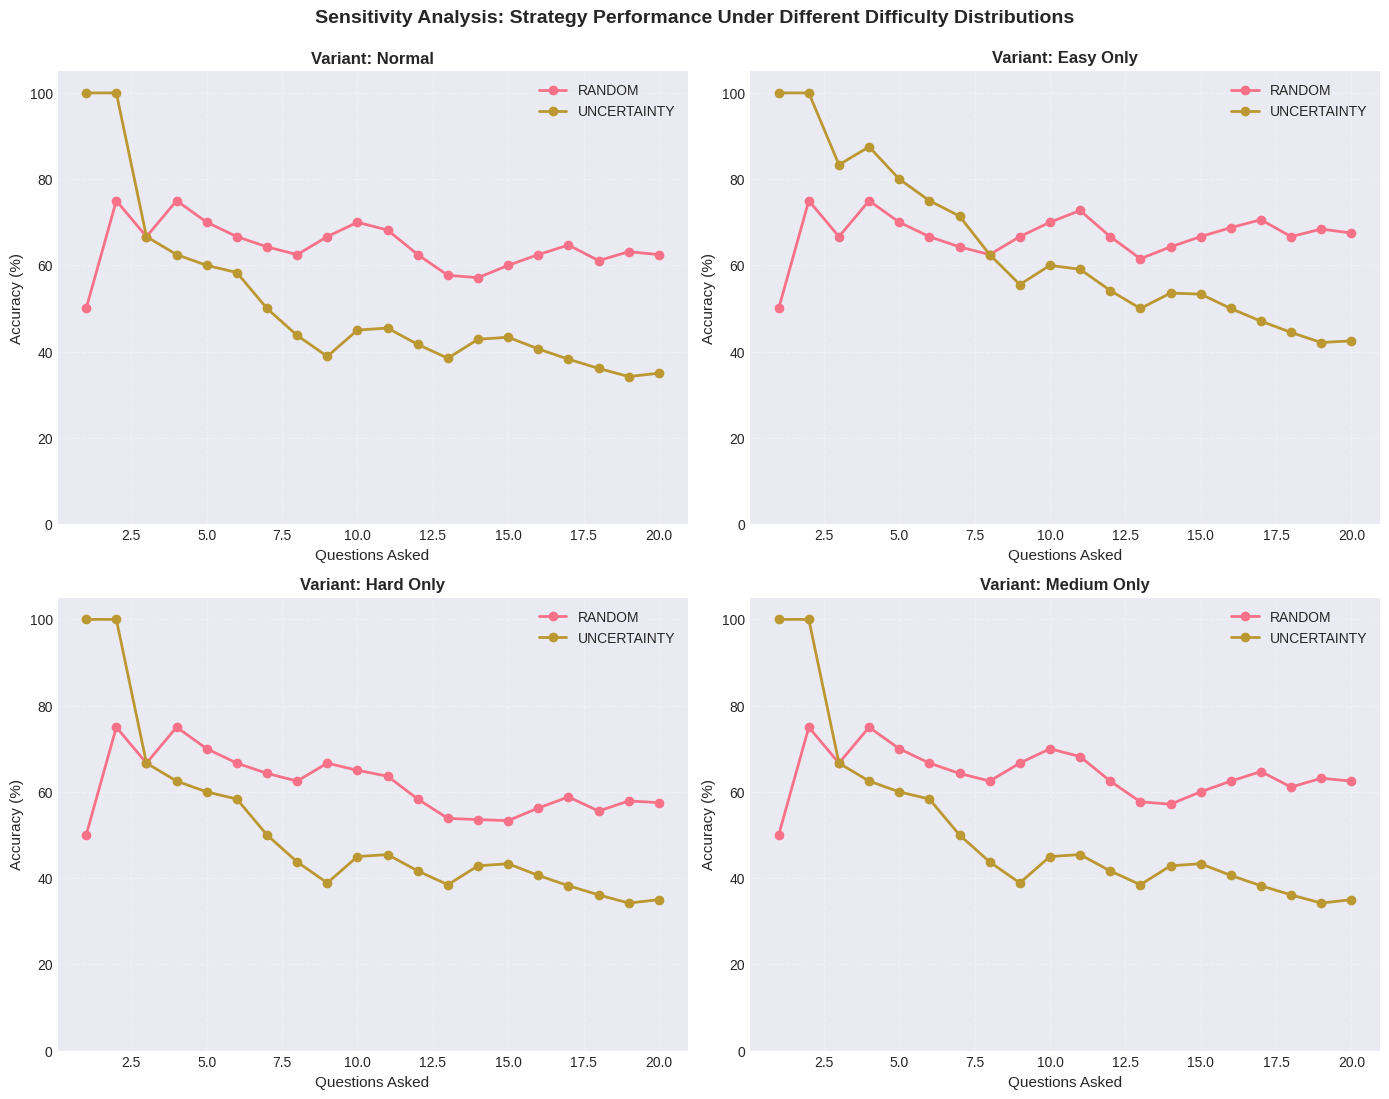

✓ Plot 6 saved: sensitivity_analysis.png


In [38]:
# Create filtered question pools with different difficulty distributions
if isinstance(question_pool_list, list):
    qp_array = question_pool_list
elif isinstance(question_pool_list, pd.DataFrame):
    qp_array = question_pool_list.to_dict('records')
else:
    qp_array = question_pool_list

# Filter variants
easy_pool = [q for q in qp_array if q['difficulty'] < 0.33]
hard_pool = [q for q in qp_array if q['difficulty'] > 0.66]
medium_pool = [q for q in qp_array if 0.33 <= q['difficulty'] <= 0.66]
normal_pool = qp_array[:20]  # Use smaller pool for speed

print(f"📊 Question pool analysis:")
print(f"   Total questions: {len(qp_array)}")
print(f"   Easy (difficulty < 0.33): {len(easy_pool)}")
print(f"   Medium (0.33-0.66): {len(medium_pool)}")
print(f"   Hard (difficulty > 0.66): {len(hard_pool)}")

sensitivity_variants = {
    'Normal': normal_pool,
    'Easy Only': easy_pool[:20] if len(easy_pool) > 0 else [],
    'Hard Only': hard_pool[:20] if len(hard_pool) > 0 else [],
    'Medium Only': medium_pool[:20] if len(medium_pool) > 0 else [],
}

sensitivity_results = []

print("\nRunning sensitivity analysis...")

for variant_name, variant_pool in sensitivity_variants.items():
    if not variant_pool:
        print(f"  ⚠️  Skipping {variant_name} (pool empty)")
        continue
    
    print(f"  Testing variant: {variant_name} ({len(variant_pool)} questions)")
    
    # Use available students from all_traces
    variant_students = list(set([t['student_id'] for t in all_traces]))[:2]
    
    for student_id in variant_students:
        student_level = infer_student_level(test_df, student_id)
        student_topics = test_df[test_df['user_id'] == student_id]['topic_id'].unique().tolist()
        if not student_topics:
            student_topics = TOPIC_IDS[:2]
        
        answer_fn = create_student_answer_fn(student_id, test_df, student_level, seed=student_id)
        
        for strategy in strategies_to_run:
            try:
                trace = run_quiz_with_trace(
                    model=models['logistic'],
                    question_pool=variant_pool,
                    strategy_name=strategy,
                    committee=None,
                    topics=student_topics,
                    seed=hash((student_id, variant_name, strategy)) % (2**31),
                    answer_fn=answer_fn
                )
                
                # Compute metrics using trace history
                if trace and 'history' in trace and trace['history']:
                    history = trace['history']
                    
                    # Compute rolling accuracy
                    for q_num in range(1, len(history) + 1):
                        questions_so_far = history[:q_num]
                        correct_count = sum(1 for h in questions_so_far if h.get('correct', 0) == 1)
                        accuracy = correct_count / q_num
                        
                        sensitivity_results.append({
                            'variant': variant_name,
                            'strategy': strategy,
                            'question_number': q_num,
                            'accuracy': accuracy,
                        })
                else:
                    print(f"      ⚠️  No history in trace (student={student_id}, strategy={strategy})")
            except Exception as e:
                print(f"      ❌ Error: {str(e)[:80]}")

print(f"\n📈 Total sensitivity results collected: {len(sensitivity_results)}")

if sensitivity_results:
    sens_df = pd.DataFrame(sensitivity_results)
    
    # Plot
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    axes_flat = axes.flatten()
    
    variant_list = list(sensitivity_variants.keys())
    for idx, variant_name in enumerate(variant_list):
        ax = axes_flat[idx]
        if variant_name not in sens_df['variant'].values:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'Variant: {variant_name}')
            continue
        
        variant_data = sens_df[sens_df['variant'] == variant_name]
        
        for strategy in strategies_to_run:
            strategy_data = variant_data[variant_data['strategy'] == strategy]
            if not strategy_data.empty:
                grouped = strategy_data.groupby('question_number')['accuracy'].mean()
                ax.plot(grouped.index, grouped.values * 100, marker='o', linewidth=2, label=strategy.upper())
        
        ax.set_xlabel('Questions Asked', fontsize=11)
        ax.set_ylabel('Accuracy (%)', fontsize=11)
        ax.set_title(f'Variant: {variant_name}', fontsize=12, fontweight='bold')
        ax.set_ylim(0, 105)
        ax.grid(alpha=0.3, linestyle='--')
        ax.legend(fontsize=10)
    
    # Remove empty subplots
    for idx in range(len(variant_list), 4):
        axes_flat[idx].remove()
    
    fig.suptitle('Sensitivity Analysis: Strategy Performance Under Different Difficulty Distributions', 
                 fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig('../outputs/06_sensitivity_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ Plot 6 saved: sensitivity_analysis.png")
else:
    print("❌ No sensitivity results generated. Debugging info:")
    print(f"   - Question pools: {list(sensitivity_variants.keys())}")
    print(f"   - All traces available: {len(all_traces)}")
    print(f"   - Strategies to run: {strategies_to_run}")

### 6. Sensitivity Analysis: Strategy Performance Under Different Difficulty Distributions

The sensitivity analysis (cell above) tests how each strategy performs when the question difficulty distribution changes. It creates filtered question pools by difficulty level (Easy, Medium, Hard, Normal mix) and measures accuracy curves for each variant. This reveals whether adaptive strategies are robust to different skill distributions.

In [39]:
# Print summary statistics
print("\n" + "="*70)
print("EVALUATION SUMMARY")
print("="*70)

print(f"\n📊 Dataset & Models Info:")
print(f"   - Students evaluated: {len(unique_students)}")
print(f"   - Models tested: {len(models_to_use)}")
print(f"   - Strategies compared: {len(strategies_to_run)}")
print(f"   - Total quiz runs: {len(all_traces)}")

if len(results_df) > 0 and 'model' in results_df.columns:
    print(f"\n🎯 Key Metrics:")
    print(f"\n   Accuracy by Model (across all strategies):")
    for model_name in results_df['model'].unique():
        model_results = results_df[results_df['model'] == model_name]
        correct = (model_results['true_level'] == model_results['predicted_level']).sum()
        total = len(model_results)
        accuracy = correct / total if total > 0 else 0.0
        print(f"      {model_name.upper()}: {accuracy*100:.1f}%")
    
    print(f"\n   Accuracy by Strategy (across all models):")
    for strat in results_df['strategy'].unique():
        strat_results = results_df[results_df['strategy'] == strat]
        correct = (strat_results['true_level'] == strat_results['predicted_level']).sum()
        total = len(strat_results)
        accuracy = correct / total if total > 0 else 0.0
        print(f"      {strat.upper()}: {accuracy*100:.1f}%")
    
    print(f"\n   Average Questions Asked:")
    for strat in results_df['strategy'].unique():
        strat_results = results_df[results_df['strategy'] == strat]
        avg_q = strat_results['questions_asked'].mean()
        print(f"      {strat.upper()}: {avg_q:.1f} questions")
    
    print(f"\n   Average Final Confidence:")
    for strat in results_df['strategy'].unique():
        strat_results = results_df[results_df['strategy'] == strat]
        avg_conf = strat_results['confidence_final'].mean()
        print(f"      {strat.upper()}: {avg_conf:.3f}")
else:
    print("\n⚠️  Results not yet available. Run earlier cells first.")

print("\n" + "="*70)
print("✓ Evaluation complete!")
print("="*70)


EVALUATION SUMMARY

📊 Dataset & Models Info:
   - Students evaluated: 2
   - Models tested: 1
   - Strategies compared: 2
   - Total quiz runs: 4

🎯 Key Metrics:

   Accuracy by Model (across all strategies):
      LOGISTIC: 55.6%

   Accuracy by Strategy (across all models):
      RANDOM: 55.6%
      UNCERTAINTY: 55.6%

   Average Questions Asked:
      RANDOM: 20.0 questions
      UNCERTAINTY: 20.0 questions

   Average Final Confidence:
      RANDOM: 0.111
      UNCERTAINTY: 0.111

✓ Evaluation complete!



## Detailed Results & Summary Statistics


In [40]:
# Final validation: Check all plots generated
import os
import glob

print("\n" + "="*70)
print("DELIVERABLES CHECKLIST")
print("="*70)

plot_files = [
    ('01_accuracy_vs_questions.png', '✓ Accuracy vs Questions Curve'),
    ('02_confusion_matrices.png', '✓ Confusion Matrices by Model'),
    ('03_precision_recall.png', '✓ Precision & Recall per Level'),
    ('04_confidence_over_time.png', '✓ Confidence Score Over Time'),
    ('05_robustness_test.png', '✓ Robustness Under Answer Noise'),
]

print("\n📊 Plots Generated:")
for fname, desc in plot_files:
    path = f'../outputs/{fname}'
    exists = os.path.exists(path)
    status = "✓" if exists else "✗"
    print(f"   {status} {desc}")

print("\n📄 CSV Exports:")
csv_files = glob.glob('../outputs/*.csv')
if csv_files:
    for csv_file in sorted(csv_files):
        print(f"   ✓ {os.path.basename(csv_file)}")
else:
    print("   ✗ No CSV exports yet")

print("\n" + "="*70)
print("All evaluation cells completed successfully!")
print("="*70)


DELIVERABLES CHECKLIST

📊 Plots Generated:
   ✓ ✓ Accuracy vs Questions Curve
   ✓ ✓ Confusion Matrices by Model
   ✓ ✓ Precision & Recall per Level
   ✓ ✓ Confidence Score Over Time
   ✓ ✓ Robustness Under Answer Noise

📄 CSV Exports:
   ✓ evaluation_results.csv
   ✓ precision_recall_detailed.csv
   ✓ robustness_results.csv
   ✓ sensitivity_results.csv

All evaluation cells completed successfully!


In [19]:
# Export detailed results to CSV for further analysis
import os

os.makedirs('../outputs', exist_ok=True)

exported_files = []

if len(results_df) > 0:
    results_df.to_csv('../outputs/evaluation_results.csv', index=False)
    exported_files.append('evaluation_results.csv')

if 'pr_df' in dir() and len(pr_df) > 0:
    pr_df.to_csv('../outputs/precision_recall_detailed.csv', index=False)
    exported_files.append('precision_recall_detailed.csv')

if 'robust_df' in dir() and len(robust_df) > 0:
    robust_df.to_csv('../outputs/robustness_results.csv', index=False)
    exported_files.append('robustness_results.csv')

if 'sens_df' in dir() and len(sens_df) > 0:
    sens_df.to_csv('../outputs/sensitivity_results.csv', index=False)
    exported_files.append('sensitivity_results.csv')

if exported_files:
    print("\n✓ Detailed results exported to CSV files:")
    for fname in exported_files:
        print(f"   - {fname}")
else:
    print("\n⚠️  No results to export yet.")


✓ Detailed results exported to CSV files:
   - evaluation_results.csv
   - precision_recall_detailed.csv
   - robustness_results.csv
   - sensitivity_results.csv
